**Import the libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


**Dataset Upload**

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving vgsales.csv to vgsales (4).csv


**Dataset Load**

In [ ]:
df = pd.read_csv("vgsales.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


**Print the first five rows**

In [ ]:
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


**Print the last five rows**

In [ ]:
df.tail()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.0,0.0,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.0,0.0,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.0,0.0,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.0,0.0,0.01
16597,16600,Spirits & Spells,GBA,2003.0,Platform,Wanadoo,0.01,0.00,0.0,0.0,0.01


Total number of rows and columns

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 16598
Number of columns: 11


**Print the name of Columns**

In [ ]:
print(df.columns.tolist())

['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']


**Check Datatypes**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


Check Statistical Summary

In [ ]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


**Check Missing Values**

In [ ]:
print("Missing values in each column:")

print(df.isnull().sum())

Missing values in each column:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64


**Check Duplicate Records**

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


**Check Missing Values Percentage**

In [ ]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

print(missing_percentage)

Year            1.632727
Publisher       0.349440
Rank            0.000000
Platform        0.000000
Name            0.000000
Genre           0.000000
NA_Sales        0.000000
EU_Sales        0.000000
JP_Sales        0.000000
Other_Sales     0.000000
Global_Sales    0.000000
dtype: float64


**Clean the Dataset**

In [ ]:

df_clean = df.copy()

df_clean = df_clean.drop_duplicates()


df_clean["Year"] = pd.to_numeric(
    df_clean["Year"], errors="coerce"
)

df_clean["Global_Sales"] = pd.to_numeric(
    df_clean["Global_Sales"], errors="coerce"
)


df_clean = df_clean.dropna(
    subset=["Global_Sales"]
)

df_clean = df_clean[
    df_clean["Global_Sales"] >= 0
]

df_clean.loc[
    df_clean["Year"].between(1950, 2035),
    "Year"
] = np.nan

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

df_clean.head()

Original dataset shape: (16598, 11)
Cleaned dataset shape: (16598, 11)


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,NaN,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,NaN,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,NaN,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,NaN,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,NaN,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


**Saving Cleaned Dataset**

In [ ]:
df_clean.to_csv(
    "vgsales_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


**EDA of Global Sales Distribution**

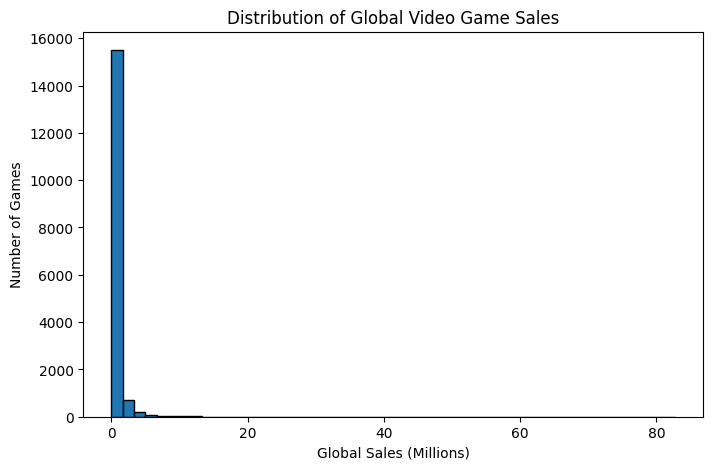

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["Global_Sales"],
    bins=50,
    edgecolor="black"
)

plt.xlabel("Global Sales (Millions)")
plt.ylabel("Number of Games")
plt.title("Distribution of Global Video Game Sales")

plt.show()

**Genre Wise Sales**

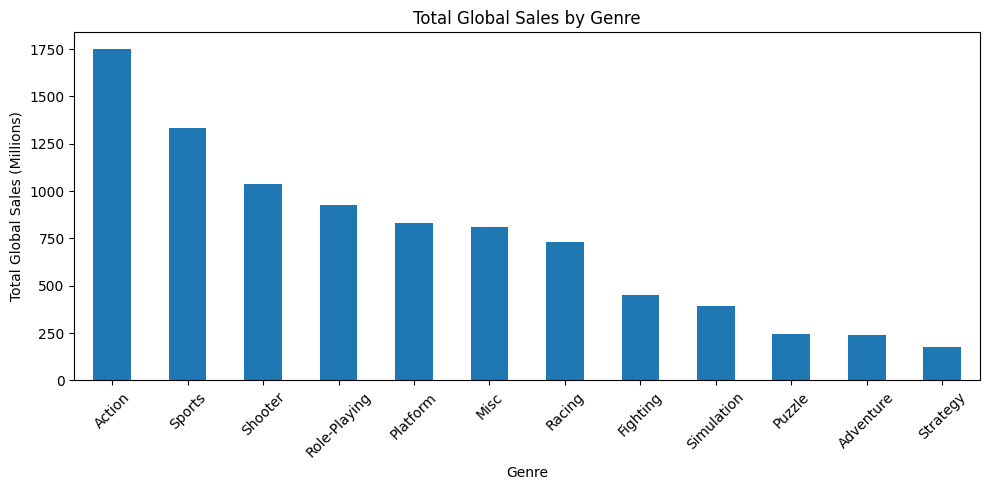

Genre
Action          1751.18
Sports          1330.93
Shooter         1037.37
Role-Playing     927.37
Platform         831.37
Misc             809.96
Racing           732.04
Fighting         448.91
Simulation       392.20
Puzzle           244.95
Adventure        239.04
Strategy         175.12
Name: Global_Sales, dtype: float64


In [ ]:
genre_sales = (
    df_clean.groupby("Genre")["Global_Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

genre_sales.plot(kind="bar")

plt.xlabel("Genre")
plt.ylabel("Total Global Sales (Millions)")
plt.title("Total Global Sales by Genre")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

print(genre_sales)

**Check Year and Global Sales Data**

In [ ]:
print("Dataset shape:", df.shape)

print("\nYear column:")
print(df["Year"].head(10))

print("\nValid Year count:", df["Year"].notna().sum())

print("\nGlobal Sales column:")
print(df["Global_Sales"].head(10))

print("\nValid Global Sales count:", df["Global_Sales"].notna().sum())

Dataset shape: (16598, 11)

Year column:
0    2006.0
1    1985.0
2    2008.0
3    2009.0
4    1996.0
5    1989.0
6    2006.0
7    2006.0
8    2009.0
9    1984.0
Name: Year, dtype: float64

Valid Year count: 16327

Global Sales column:
0    82.74
1    40.24
2    35.82
3    33.00
4    31.37
5    30.26
6    30.01
7    29.02
8    28.62
9    28.31
Name: Global_Sales, dtype: float64

Valid Global Sales count: 16598


**Year Wise Sales**

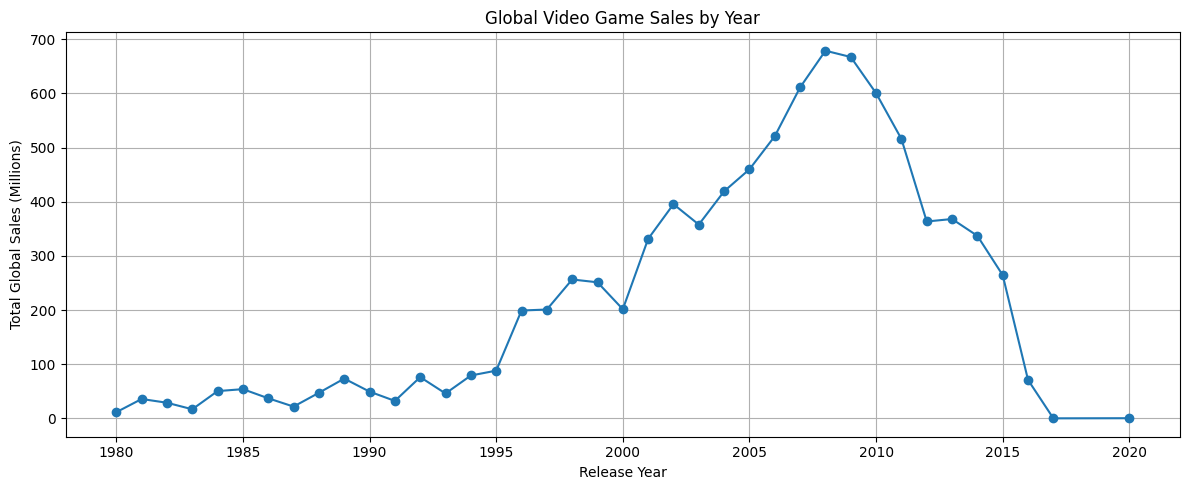

In [ ]:
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df["Global_Sales"] = pd.to_numeric(
    df["Global_Sales"], errors="coerce"
)

year_data = df.dropna(subset=["Year", "Global_Sales"]).copy()

year_sales = year_data.groupby("Year")["Global_Sales"].sum().sort_index()

plt.figure(figsize=(12, 5))

plt.plot(
    year_sales.index,
    year_sales.values,
    marker="o"
)

plt.xlabel("Release Year")
plt.ylabel("Total Global Sales (Millions)")
plt.title("Global Video Game Sales by Year")
plt.grid(True)
plt.tight_layout()
plt.show()

**Platform Wise Sales**

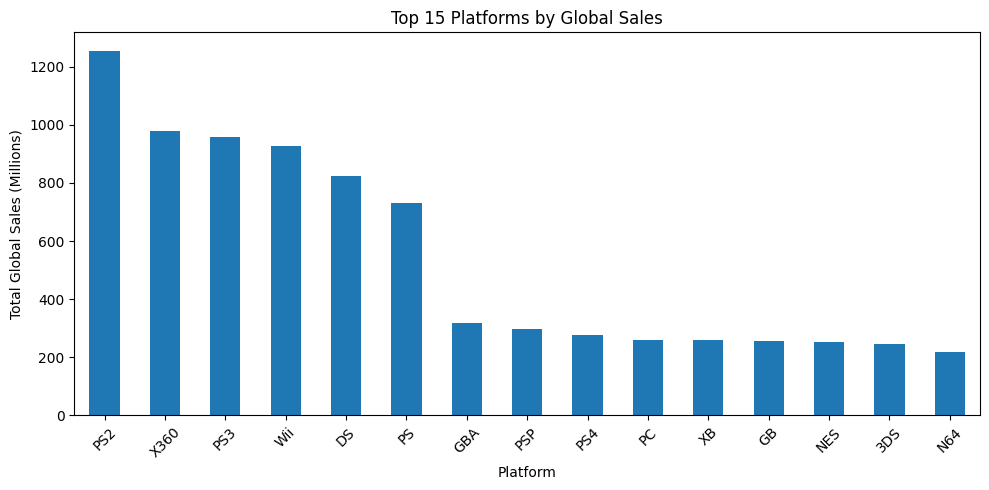

In [ ]:
platform_sales = (
    df_clean.groupby("Platform")["Global_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 5))

platform_sales.plot(kind="bar")

plt.xlabel("Platform")
plt.ylabel("Total Global Sales (Millions)")
plt.title("Top 15 Platforms by Global Sales")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**Select input features and target**

**Input features (X) Platform Genre Year Publisher Target variable (y): Global_Sales bold text**

In [ ]:
features = [
    "Platform",
    "Genre",
    "Year",
    "Publisher"
]

target = "Global_Sales"

X = df_clean[features].copy()

y = df_clean[target].copy()

print("Input features:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Input features:
  Platform         Genre  Year Publisher
0      Wii        Sports   NaN  Nintendo
1      NES      Platform   NaN  Nintendo
2      Wii        Racing   NaN  Nintendo
3      Wii        Sports   NaN  Nintendo
4       GB  Role-Playing   NaN  Nintendo

Target variable:
0    82.74
1    40.24
2    35.82
3    33.00
4    31.37
Name: Global_Sales, dtype: float64


**Encode Categorical data and Handle Missing Values**

In [ ]:


# Define input features
numerical_features = ["Year"]

categorical_features = ["Platform", "Genre", "Publisher"]

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


**Split the Dataset into Training and Testing Data**

In [ ]:
from sklearn.model_selection import train_test_split

X = df[["Platform", "Genre", "Year", "Publisher"]]
y = df["Global_Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (13278, 4)
Testing shape: (3320, 4)


**Train the Linear Regression Model and Evaluate**

In [ ]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

# Train the model
linear_model.fit(X_train, y_train)

# Predict sales
y_pred_linear = linear_model.predict(X_test)

print("Linear Regression training completed!")
mae_linear = mean_absolute_error(
    y_test,
    y_pred_linear
)

mse_linear = mean_squared_error(
    y_test,
    y_pred_linear
)

rmse_linear = np.sqrt(mse_linear)

r2_linear = r2_score(
    y_test,
    y_pred_linear
)

print("Linear Regression Results")
print("--------------------------")
print("MAE:", mae_linear)
print("MSE:", mse_linear)
print("RMSE:", rmse_linear)
print("R2 Score:", r2_linear)

Linear Regression training completed!
Linear Regression Results
--------------------------
MAE: 0.5590315944569622
MSE: 3.8253852175673164
RMSE: 1.9558592018770975
R2 Score: 0.08948968977415617


**Train the Decision Tree Regressor and Evaluate**

In [ ]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                random_state=42,
                min_samples_leaf=2
            )
        )
    ]
)

# Train model
decision_tree_model.fit(
    X_train,
    y_train
)

# Predict sales
y_pred_tree = decision_tree_model.predict(
    X_test
)

print("Decision Tree training completed!")
mae_tree = mean_absolute_error(
    y_test,
    y_pred_tree
)

mse_tree = mean_squared_error(
    y_test,
    y_pred_tree
)

rmse_tree = np.sqrt(mse_tree)

r2_tree = r2_score(
    y_test,
    y_pred_tree
)

print("Decision Tree Results")
print("----------------------")
print("MAE:", mae_tree)
print("MSE:", mse_tree)
print("RMSE:", rmse_tree)
print("R2 Score:", r2_tree)

Decision Tree training completed!
Decision Tree Results
----------------------
MAE: 0.547968971883799
MSE: 3.965027591782558
RMSE: 1.991237703485588
R2 Score: 0.05625229948898913


**Train the Random Forest Regressor and Evaluate**

In [ ]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=150,
                random_state=42,
                n_jobs=-1,
                min_samples_leaf=2
            )
        )
    ]
)

# Train model
random_forest_model.fit(
    X_train,
    y_train
)

# Predict sales
y_pred_rf = random_forest_model.predict(
    X_test
)

print("Random Forest training completed!")
mae_rf = mean_absolute_error(
    y_test,
    y_pred_rf
)

mse_rf = mean_squared_error(
    y_test,
    y_pred_rf
)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(
    y_test,
    y_pred_rf
)

print("Random Forest Results")
print("---------------------")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest training completed!
Random Forest Results
---------------------
MAE: 0.5181135620032568
MSE: 3.728895098009795
RMSE: 1.9310347221139745
R2 Score: 0.11245606928767282


**Compare the Three Models**

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree Regressor",
        "Random Forest Regressor"
    ],

    "MAE": [
        mae_linear,
        mae_tree,
        mae_rf
    ],

    "MSE": [
        mse_linear,
        mse_tree,
        mse_rf
    ],

    "RMSE": [
        rmse_linear,
        rmse_tree,
        rmse_rf
    ],

    "R2 Score": [
        r2_linear,
        r2_tree,
        r2_rf
    ]
})

results = results.sort_values(
    by="MAE"
).reset_index(drop=True)

results

,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest Regressor,0.518114,3.728895,1.931035,0.112456
1,Decision Tree Regressor,0.547969,3.965028,1.991238,0.056252
2,Linear Regression,0.559032,3.825385,1.955859,0.089490


**Perform 5-Fold Cross-Validation**


**Define 5-Fold Cross-Validation**

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Cross-Validation initialized!")

5-Fold Cross-Validation initialized!


**Define the Three Models**

In [ ]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree Regressor": DecisionTreeRegressor(
        random_state=42,
        min_samples_leaf=2
    ),

    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    )
}

**Run Cross-Validation**

In [ ]:
cv_results = []

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "MSE": "neg_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=1
    )

    # Convert negative error scores into positive values
    mae_scores = -scores["test_MAE"]
    mse_scores = -scores["test_MSE"]
    rmse_scores = np.sqrt(mse_scores)
    r2_scores = scores["test_R2"]

    cv_results.append({
        "Model": name,
        "Mean CV MAE": mae_scores.mean(),
        "Std CV MAE": mae_scores.std(ddof=1),
        "Mean CV MSE": mse_scores.mean(),
        "Mean CV RMSE": rmse_scores.mean(),
        "Mean CV R2": r2_scores.mean()
    })

    print(f"{name} completed!")

Linear Regression completed!
Decision Tree Regressor completed!
Random Forest Regressor completed!


**Display the Cross-Validation Results**

In [ ]:
cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="Mean CV MAE"
).reset_index(drop=True)

cv_results_df

,Model,Mean CV MAE,Std CV MAE,Mean CV MSE,Mean CV RMSE,Mean CV R2
0,Random Forest Regressor,0.472040,0.010242,1.749402,1.320130,0.101786
1,Decision Tree Regressor,0.509208,0.014868,2.035834,1.424704,-0.048074
2,Linear Regression,0.521307,0.018796,1.694105,1.296463,0.139688


**Save the Cross-Validation Results**

In [ ]:
cv_results_df.to_csv(
    "cross_validation_results.csv",
    index=False
)

print("Cross-validation results saved successfully!")

Cross-validation results saved successfully!


**Hyperparameter Tuning**

**Decision Tree Hyperparameter Tuning**

In [ ]:
# Create Decision Tree Pipeline

dt_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

# Define parameters

dt_params = {
    "model__max_depth": [5, 10, 20, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

# Apply Grid Search

dt_grid = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_params,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

# Train

dt_grid.fit(X_train, y_train)

print("Best Decision Tree Parameters:")
print(dt_grid.best_params_)

print("\nBest Cross Validation MAE:")
print(-dt_grid.best_score_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Decision Tree Parameters:
{'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5}

Best Cross Validation MAE:
0.516602398381906


**Random Forest Hyperparameter Tuning**

In [ ]:
# Create Random Forest Pipeline

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

# Define parameters

rf_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [20, None],
    "model__min_samples_leaf": [1, 2]
}

# Apply Grid Search

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

# Train

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross Validation MAE:")
print(-rf_grid.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Random Forest Parameters:
{'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}

Best Cross Validation MAE:
0.4779271204750577


**Hyperparameter Tuning Comparison**

In [ ]:
tuning_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest"
    ],
    "Best CV MAE": [
        -dt_grid.best_score_,
        -rf_grid.best_score_
    ]
})

print(tuning_results)

           Model  Best CV MAE
0  Decision Tree     0.516602
1  Random Forest     0.477927


**Prepare Model for Confusion Matrix**

In [ ]:
# Linear Regression
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

# Tuned models
best_dt_model = dt_grid.best_estimator_
best_rf_model = rf_grid.best_estimator_

print("All models are ready!")

All models are ready!


**Generate Sales Predictions**

In [ ]:
# Predictions on test data

linear_predictions = linear_model.predict(X_test)

dt_predictions = best_dt_model.predict(X_test)

rf_predictions = best_rf_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


**Convert Sales into Low and High Categories**

In [ ]:
# Threshold = 1 million copies

def convert_sales_category(sales):
    return np.where(sales < 1, "Low Sales", "High Sales")


# Actual categories

actual_categories = convert_sales_category(y_test)

# Predicted categories

linear_categories = convert_sales_category(linear_predictions)

dt_categories = convert_sales_category(dt_predictions)

rf_categories = convert_sales_category(rf_predictions)

print("Sales categories generated successfully!")

Sales categories generated successfully!


**Generate Confusion Matrices**

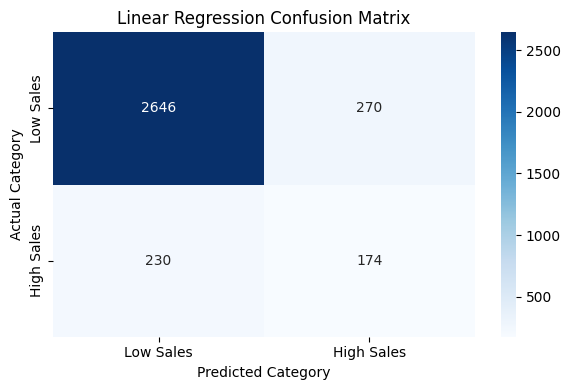


 Linear Regression
              precision    recall  f1-score   support

  High Sales       0.39      0.43      0.41       404
   Low Sales       0.92      0.91      0.91      2916

    accuracy                           0.85      3320
   macro avg       0.66      0.67      0.66      3320
weighted avg       0.86      0.85      0.85      3320



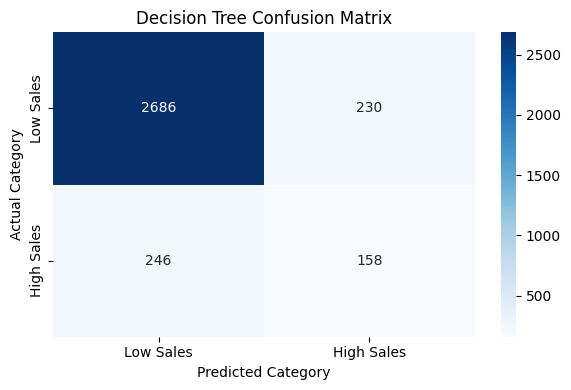


 Decision Tree
              precision    recall  f1-score   support

  High Sales       0.41      0.39      0.40       404
   Low Sales       0.92      0.92      0.92      2916

    accuracy                           0.86      3320
   macro avg       0.66      0.66      0.66      3320
weighted avg       0.85      0.86      0.86      3320



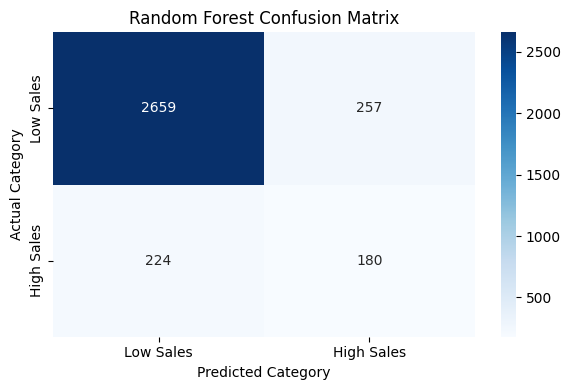


 Random Forest
              precision    recall  f1-score   support

  High Sales       0.41      0.45      0.43       404
   Low Sales       0.92      0.91      0.92      2916

    accuracy                           0.86      3320
   macro avg       0.67      0.68      0.67      3320
weighted avg       0.86      0.86      0.86      3320



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

models_categories = {
    "Linear Regression": linear_categories,
    "Decision Tree": dt_categories,
    "Random Forest": rf_categories
}

for model_name, predictions in models_categories.items():

    cm = confusion_matrix(
        actual_categories,
        predictions,
        labels=["Low Sales", "High Sales"]
    )

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Low Sales", "High Sales"],
        yticklabels=["Low Sales", "High Sales"]
    )

    plt.xlabel("Predicted Category")
    plt.ylabel("Actual Category")
    plt.title(model_name + " Confusion Matrix")

    plt.tight_layout()
    plt.show()

    print("\n", model_name)
    print(classification_report(
        actual_categories,
        predictions,
        zero_division=0
    ))

**Save Confusion Matrices**

In [ ]:
import os

os.makedirs("project_results", exist_ok=True)

for model_name, predictions in models_categories.items():

    cm = confusion_matrix(
        actual_categories,
        predictions,
        labels=["Low Sales", "High Sales"]
    )

    cm_df = pd.DataFrame(
        cm,
        index=["Actual Low Sales", "Actual High Sales"],
        columns=["Predicted Low Sales", "Predicted High Sales"]
    )

    filename = model_name.lower().replace(" ", "_")

    cm_df.to_csv(
        f"project_results/{filename}_confusion_matrix.csv"
    )

print("All confusion matrices saved successfully!")

All confusion matrices saved successfully!


**Final Model Evaluation**

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

final_models = {
    "Linear Regression": linear_model,
    "Tuned Decision Tree": best_dt_model,
    "Tuned Random Forest": best_rf_model
}

evaluation_results = []

for name, model in final_models.items():

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    evaluation_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

final_results = pd.DataFrame(evaluation_results)

print(final_results)

                 Model       MAE       MSE      RMSE  R2 Score
0    Linear Regression  0.559032  3.825385  1.955859  0.089490
1  Tuned Decision Tree  0.546412  3.950115  1.987490  0.059802
2  Tuned Random Forest  0.518326  3.730711  1.931505  0.112024


**Final Model Performance Graph**

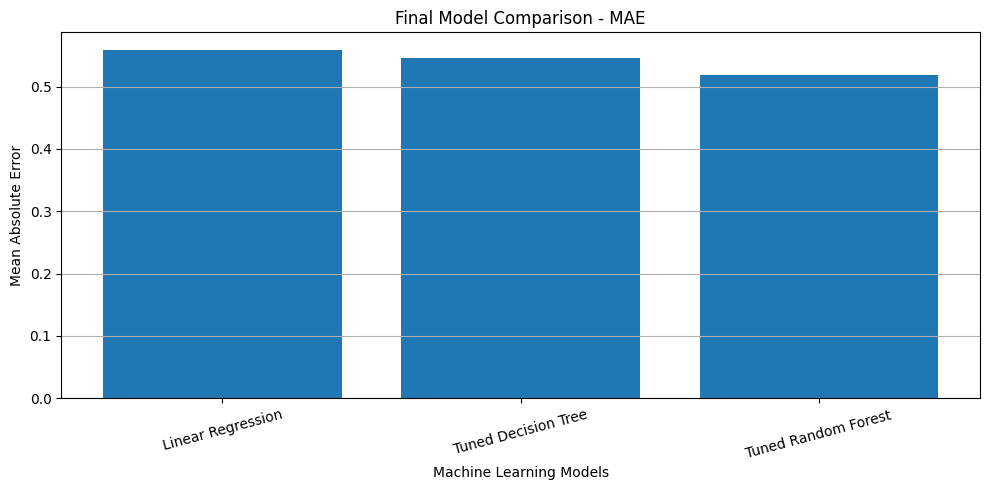

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    final_results["Model"],
    final_results["MAE"]
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Absolute Error")

plt.title("Final Model Comparison - MAE")

plt.xticks(rotation=15)

plt.grid(axis="y")

plt.tight_layout()
plt.show()

**Select Best Model**

In [ ]:
from sklearn.model_selection import cross_val_score

cv_selection_results = []

for name, model in final_models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    cv_mae = -scores.mean()

    cv_std = scores.std()

    cv_selection_results.append({
        "Model": name,
        "Mean CV MAE": cv_mae,
        "CV Standard Deviation": cv_std
    })

cv_selection_df = pd.DataFrame(cv_selection_results)

print(cv_selection_df)

best_model_name = cv_selection_df.loc[
    cv_selection_df["Mean CV MAE"].idxmin(),
    "Model"
]

best_model = final_models[best_model_name]

print("\nBest Selected Model:", best_model_name)

                 Model  Mean CV MAE  CV Standard Deviation
0    Linear Regression     0.522140               0.012087
1  Tuned Decision Tree     0.516602               0.021668
2  Tuned Random Forest     0.477927               0.017775

Best Selected Model: Tuned Random Forest


**Save Final Machine Learning Model**

In [ ]:
import joblib

# Save complete pipeline

joblib.dump(
    best_model,
    "project_results/best_video_game_sales_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


**Save Final Evaluation Results**

In [ ]:
# Save model comparison

final_results.to_csv(
    "project_results/final_model_comparison.csv",
    index=False
)

# Save CV comparison

cv_selection_df.to_csv(
    "project_results/final_cross_validation_results.csv",
    index=False
)

# Save tuning results

tuning_results.to_csv(
    "project_results/hyperparameter_tuning_results.csv",
    index=False
)

print("All evaluation results saved successfully!")

All evaluation results saved successfully!


**Download Project Results**

In [ ]:
import shutil

shutil.make_archive(
    "Video_Game_Sales_Project_Results",
    "zip",
    "project_results"
)

from google.colab import files

files.download("Video_Game_Sales_Project_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>